# Bangladesh Chest X-ray Dataset — curation, release export, EDA and benchmarks
## Kaggle notebook for a Data in Brief–style dataset preprint
**Source:** [A Primary Chest X-ray Dataset of Normal Bangladesh, version 5](https://data.mendeley.com/datasets/wndbd5r26y/5), DOI **10.17632/wndbd5r26y.5**.

This is a new chest-X-ray notebook adapted from the *structure* of your supplied diabetes EDA notebook and the supplied Data in Brief template. It does not use diabetes or brain-tumor data. The template is a journal data-article template, not an SSRN-specific template. Nothing is submitted or uploaded by this notebook.

**Kaggle:** enable **Internet** and a **GPU**, then Run All. Data are downloaded directly from Mendeley; no attached Kaggle dataset, Google Drive, Colab upload or local source file is needed. Session-disk caching is automatic.

**Expected audit:** 2,626 source images → 25 same-label duplicate copies removed + 96 images in conflicting-label groups excluded → 2,505 retained; 0 unreadable. These are assertions to verify, never numbers imposed on the data. The source page's stated 3,355 images disagrees with the previously verified ZIP; the archive and computed manifests govern this workflow.

**Outputs:** a self-contained `Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE.zip`, cleaning audit, image statistics and figures, manifests/data dictionary, author-completion notes, benchmark predictions/metrics, and a manuscript-support ZIP. The cleaned dataset ZIP is created **before** GPU training, so it is available even if training is interrupted. “v6 candidate” is a local release label; it becomes Mendeley version 6 only after you publish it there and verify its assigned DOI.

The native image bytes/resolution are retained. Cleaning removes exact decoded-image repetitions; it does not relabel images, remove clinically unusual images, or claim to detect all near-duplicates/patient overlap. Benchmarks assess utility on this split, not clinical validity. Human annotation provenance, ethics/consent, patient separation and visible identifying text require author verification.

**Download correction:** removes the dependency on Mendeley’s file-list API. Direct source access still depends on Mendeley allowing the request. If the archive endpoint also returns 403, use the authorized-link option in Section 2 or restore source access; enabling Internet alone does not guarantee that Mendeley accepts the request.


## 0. Dependencies

In [1]:
import sys, subprocess, importlib.util
needed = {'requests':'requests', 'imagehash':'ImageHash==4.3.2', 'sklearn':'scikit-learn',
          'scipy':'scipy', 'pandas':'pandas', 'matplotlib':'matplotlib', 'seaborn':'seaborn', 'tqdm':'tqdm', 'jinja2':'jinja2'}
missing = [package for module, package in needed.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Keep Kaggle's matched torch/torchvision installation; do not upgrade them independently.

## 1. Configuration and reusable utilities

In [2]:
from pathlib import Path
from collections import defaultdict
import os, sys, json, hashlib, zipfile, shutil, random, time, gc, inspect, platform
from datetime import datetime, timezone
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import imagehash
from scipy.ndimage import laplace
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, FileLink, HTML

ROOT = Path('/kaggle/working/chest_xray_dataset_v6')
DOWNLOADS, RAW, REPORTS, FIGURES, EXPORTS = [ROOT / x for x in ['downloads','raw','reports','figures','exports']]
for folder in (DOWNLOADS, RAW, REPORTS, FIGURES, EXPORTS): folder.mkdir(parents=True, exist_ok=True)
DATASET_ID, SOURCE_VERSION = 'wndbd5r26y', 5
SOURCE_DOI = '10.17632/wndbd5r26y.5'
SOURCE_URL = 'https://data.mendeley.com/datasets/wndbd5r26y/5'
EXPECTED_ARCHIVE_SHA256 = '3d07a6f0d3ba37c9a72edba45d05e307ab57ebf2ba2effe2b3373da448dcad0c'
EXPECTED_COUNTS = dict(raw_images=2626, duplicate_copies=25, conflicting_label_images=96, unreadable=0, retained=2505)
STRICT_EXPECTED_AUDIT = True  # Stops on a changed archive/count; inspect reports rather than forcing totals.
EXPORT_CLEAN_DATASET = True
RUN_NEAR_DUPLICATE_REVIEW = True
PHASH_MAX_DISTANCE = 4  # Candidate threshold, NOT proof that two X-rays are the same patient/image.
RUN_BENCHMARKS = True
BENCHMARK_MODELS = ['resnet18','resnet50','densenet121','efficientnet_b0','mobilenet_v3_large']
BENCHMARK_SEEDS = [42, 43, 44]  # Set [42,43,44,45,46] for five-seed reporting.
EPOCHS, BATCH_SIZE, NUM_WORKERS = 12, 16, 2
IMAGE_SIZE, SPLIT_SEED, VALIDATION_FRACTION = 224, 42, 0.20
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 1e-4
KEEP_CHECKPOINTS = False  # Retain per-run weights if True; predictions/history are always saved.
PRETRAINED = True
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','font.size':11})

def atomic_json(path, data):
    path = Path(path); temporary = path.with_suffix('.tmp')
    temporary.write_text(json.dumps(data, indent=2, allow_nan=False), encoding='utf-8'); temporary.replace(path)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(4*1024*1024), b''): h.update(chunk)
    return h.hexdigest()

def pixel_hash(image):
    # Matches the previously audited definition, before any resizing or grayscale conversion.
    rgb = ImageOps.exif_transpose(image).convert('RGB')
    h = hashlib.sha256(); h.update(str(rgb.size).encode('ascii')); h.update(rgb.tobytes())
    return h.hexdigest()

def save_figure(name):
    plt.tight_layout(); plt.savefig(FIGURES / (name+'.png'), dpi=300, bbox_inches='tight')
    plt.savefig(FIGURES / (name+'.pdf'), bbox_inches='tight'); plt.show(); plt.close()

session = requests.Session()
session.mount('https://', HTTPAdapter(max_retries=Retry(total=4, backoff_factor=2, status_forcelist=[429,500,502,503,504])))
session.headers.update({'User-Agent':'Chest-Xray-dataset-curation/1.0'})
print('Outputs:', ROOT)

Outputs: /kaggle/working/chest_xray_dataset_v6


## 2. Direct, checksum-pinned download and safe extraction
This corrected cell downloads the exact version-5 image ZIP without calling the file-list API that returned HTTP 403. It checks a valid cached archive first, then verifies downloaded bytes against the previously audited size and SHA-256. A denied download is reported explicitly; it is never treated as valid data.


In [4]:
# Download the exact Mendeley version-5 archive directly from its
# verified public storage destination. No file-list API or local upload.
import hashlib
import json
import shutil
import zipfile
from pathlib import Path

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from tqdm.auto import tqdm

PINNED_FILENAME = (
    "Chest-X-Ray Epic Hospital Chittagong, Bangladesh pneumonia.zip"
)
PINNED_FILE_ID = "53b586e5-c215-4083-bd59-83e0ad2de83a"
PINNED_SIZE = 524339616
PINNED_SHA256 = (
    "3d07a6f0d3ba37c9a72edba45d05e307ab57ebf2ba2effe2b3373da448dcad0c"
)

# Actual unsigned public URL observed in Mendeley's download redirect.
PUBLIC_DOWNLOAD_URL = (
    "https://prod-dcd-datasets-public-files-eu-west-1"
    ".s3.eu-west-1.amazonaws.com/"
    "8bae7fac-e234-4cdb-b1ef-756a926329fc"
)

# Reuse the folders configured earlier in your notebook.
DOWNLOADS = Path(DOWNLOADS)
RAW = Path(RAW)
REPORTS = Path(REPORTS)

for folder in (DOWNLOADS, RAW, REPORTS):
    folder.mkdir(parents=True, exist_ok=True)

if DATASET_ID != "wndbd5r26y" or SOURCE_VERSION != 5:
    raise ValueError("This cell is specifically for wndbd5r26y version 5.")

if EXPECTED_ARCHIVE_SHA256 != PINNED_SHA256:
    raise ValueError("The configured checksum differs from the pinned archive.")


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def valid_archive(path):
    path = Path(path)
    return (
        path.is_file()
        and path.stat().st_size == PINNED_SIZE
        and sha256_file(path) == PINNED_SHA256
        and zipfile.is_zipfile(path)
    )


session = requests.Session()
session.headers.update({
    "User-Agent": "Chest-Xray-dataset-curation/1.0",
    "Accept-Encoding": "identity",
})
session.mount(
    "https://",
    HTTPAdapter(
        max_retries=Retry(
            total=4,
            backoff_factor=2,
            status_forcelist=[429, 500, 502, 503, 504],
            allowed_methods=["GET"],
        )
    ),
)

archive_path = DOWNLOADS / PINNED_FILENAME
partial = archive_path.with_suffix(archive_path.suffix + ".part")
source_hash = PINNED_SHA256

if valid_archive(archive_path):
    download_method = "verified_cache"
    print("Using checksum-verified cached archive.")

elif valid_archive(partial):
    partial.replace(archive_path)
    download_method = "verified_completed_partial"
    print("Recovered a fully downloaded, checksum-verified archive.")

else:
    print("Downloading directly from Mendeley's public file storage...")

    try:
        with session.get(
            PUBLIC_DOWNLOAD_URL,
            stream=True,
            timeout=(30, 180),
        ) as response:
            if response.status_code in (401, 403):
                raise RuntimeError(
                    f"Public storage returned HTTP {response.status_code}. "
                    "This URL was accessible during verification, but access "
                    "from this Kaggle session is still denied. A code change "
                    "cannot guarantee removal of a server-side restriction."
                )

            response.raise_for_status()

            content_type = response.headers.get("Content-Type", "").lower()
            if "text/html" in content_type or "application/json" in content_type:
                raise RuntimeError("The server returned a page instead of the ZIP.")

            digest = hashlib.sha256()
            written = 0

            with partial.open("wb") as output, tqdm(
                total=PINNED_SIZE,
                unit="B",
                unit_scale=True,
                desc="Downloading ZIP",
            ) as bar:
                for block in response.iter_content(chunk_size=1024 * 1024):
                    if not block:
                        continue

                    written += len(block)
                    if written > PINNED_SIZE:
                        raise RuntimeError("Unexpected archive size; download stopped.")

                    output.write(block)
                    digest.update(block)
                    bar.update(len(block))

        if written != PINNED_SIZE:
            raise RuntimeError(
                f"Incomplete download: {written:,} of {PINNED_SIZE:,} bytes."
            )

        if digest.hexdigest() != PINNED_SHA256:
            raise RuntimeError(
                "SHA-256 mismatch. The downloaded file will not be used."
            )

        if not zipfile.is_zipfile(partial):
            raise RuntimeError("The downloaded file is not a valid ZIP.")

        partial.replace(archive_path)
        download_method = "verified_public_storage_download"

    except Exception:
        partial.unlink(missing_ok=True)
        raise

print("Verified archive SHA-256:", source_hash)

source_metadata = [{
    "filename": PINNED_FILENAME,
    "id": PINNED_FILE_ID,
    "size_bytes": PINNED_SIZE,
    "sha256": source_hash,
    "source_version": 5,
    "source_doi": "10.17632/wndbd5r26y.5",
    "download_url": PUBLIC_DOWNLOAD_URL,
    "metadata_origin": "Pinned v5 metadata; public URL from Mendeley redirect",
    "download_method": download_method,
}]

metadata_path = REPORTS / "source_files.json"
metadata_temp = metadata_path.with_suffix(".json.tmp")
metadata_temp.write_text(
    json.dumps(source_metadata, indent=2),
    encoding="utf-8",
)
metadata_temp.replace(metadata_path)

# Safely extract only after successful archive verification.
marker = RAW / ".archive_sha256"

if not marker.exists() or marker.read_text().strip() != source_hash:
    # RAW must be the dedicated extraction folder set in your configuration.
    base = RAW.resolve()
    if (
        base == Path(base.anchor)
        or base == Path.cwd().resolve()
        or base in archive_path.resolve().parents
        or base == REPORTS.resolve()
        or base in REPORTS.resolve().parents
    ):
        raise RuntimeError("RAW must be a dedicated source-extraction folder.")

    with zipfile.ZipFile(archive_path) as archive:
        for info in archive.infolist():
            target = (base / info.filename).resolve()

            if not target.is_relative_to(base):
                raise RuntimeError(f"Unsafe ZIP path: {info.filename}")

            if ((info.external_attr >> 16) & 0o170000) == 0o120000:
                raise RuntimeError("ZIP symlinks are not supported.")

        if RAW.exists():
            shutil.rmtree(RAW)
        RAW.mkdir(parents=True, exist_ok=True)

        print("Extracting verified source archive...")
        archive.extractall(RAW)

    marker.write_text(source_hash, encoding="utf-8")
else:
    print("Source archive was already extracted.")

print("Source files ready:", RAW)
print("Continue with the image audit and cleaning cells.")

Verified archive SHA-256: 3d07a6f0d3ba37c9a72edba45d05e307ab57ebf2ba2effe2b3373da448dcad0c
Extracting verified source archive...
Source files ready: /kaggle/working/chest_xray_dataset_v6/raw
Continue with the image audit and cleaning cells.


## 3. Image inventory, exact deduplication and label-conflict audit
Decode with Pillow, apply EXIF orientation, convert to RGB and hash dimensions plus pixels using SHA-256. File-byte SHA-256 is also recorded. A renamed/losslessly re-encoded image with identical decoded pixels is an exact duplicate; JPEG re-compression and crops need not match.

Rules: (1) exclude unreadable images; (2) if an identical-image group has multiple class labels, exclude **all** members rather than guessing the correct diagnosis; (3) otherwise retain one member, preferring the original test split, then lexical path order. Preserve the remaining original train/test membership. No image-quality threshold changes this policy.

In [5]:
EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
def discover_split(root, aliases):
    matches = [p for p in root.rglob('*') if p.is_dir() and p.name.lower() in aliases
               and any(f.is_file() and f.suffix.lower() in EXTENSIONS for f in p.rglob('*'))]
    if len(matches) != 1: raise RuntimeError(f'Ambiguous/missing split {aliases}: {matches}')
    return matches[0]

def audit_images(raw_root):
    groups, unreadable, records = defaultdict(list), [], []
    for split, aliases in [('test',{'test','testing'}), ('train',{'train','training'})]:
        base = discover_split(raw_root, aliases)
        paths = sorted(p for p in base.rglob('*') if p.is_file() and p.suffix.lower() in EXTENSIONS
                       and '__MACOSX' not in p.parts and not p.name.startswith('._'))
        for path in tqdm(paths, desc=f'Audit {split}'):
            rel = path.relative_to(base)
            if len(rel.parts) < 2: raise RuntimeError(f'Image has no class folder: {path}')
            label = rel.parts[0].strip().lower()
            if label not in {'normal','pneumonia'}: raise RuntimeError(f'Unexpected class {label!r}.')
            row = dict(source_relative_path=path.relative_to(raw_root).as_posix(), original_split=split,
                       class_name=label, file_bytes=path.stat().st_size, file_sha256=sha256_file(path))
            try:
                with Image.open(path) as im:
                    fmt, mode = im.format, im.mode
                    rgb = ImageOps.exif_transpose(im).convert('RGB'); rgb.load()
                    row.update(pixel_sha256=pixel_hash(im), width=rgb.width, height=rgb.height,
                               source_format=fmt, source_mode=mode, frames=int(getattr(im,'n_frames',1)))
                    if row['frames'] != 1: raise ValueError('Multi-frame image requires explicit handling.')
                groups[row['pixel_sha256']].append(row)
            except (OSError,ValueError) as exc:
                row.update(status='unreadable', reason=str(exc)); unreadable.append(row)
            records.append(row)
    for digest, members in groups.items():
        if len({r['class_name'] for r in members}) > 1:
            for r in members: r.update(status='conflicting_label', reason='Identical decoded pixels have different class labels', retained_id='')
        else:
            winner = members[0]
            for j,r in enumerate(members):
                r.update(status='retained' if j==0 else 'duplicate_copy',
                         reason='Canonical retained image' if j==0 else 'Exact duplicate; test-first retention', retained_id=digest)
    inventory = pd.DataFrame(records)
    summary = dict(raw_images=len(records), duplicate_copies=int((inventory.status=='duplicate_copy').sum()),
                   conflicting_label_images=int((inventory.status=='conflicting_label').sum()),
                   unreadable=len(unreadable), retained=int((inventory.status=='retained').sum()))
    assert sum(summary[k] for k in ['duplicate_copies','conflicting_label_images','unreadable','retained']) == summary['raw_images']
    return inventory, summary

inventory, audit_summary = audit_images(RAW)
inventory.to_csv(REPORTS/'source_inventory_and_decisions.csv', index=False)
inventory.groupby(['original_split','class_name','status']).size().rename('images').to_csv(REPORTS/'decision_counts_by_split_class.csv')
inventory[inventory.status=='duplicate_copy'].to_csv(REPORTS/'removed_duplicate_copies.csv', index=False)
inventory[inventory.status=='conflicting_label'].to_csv(REPORTS/'excluded_conflicting_labels.csv', index=False)
inventory[inventory.status=='unreadable'].to_csv(REPORTS/'unreadable_images.csv', index=False)
atomic_json(REPORTS/'cleaning_summary.json', audit_summary)
comparison = pd.DataFrame({'expected':EXPECTED_COUNTS, 'observed':audit_summary})
comparison['matches'] = comparison.expected == comparison.observed
display(comparison); comparison.to_csv(REPORTS/'expected_vs_observed.csv')
if STRICT_EXPECTED_AUDIT and not comparison.matches.all():
    raise RuntimeError('Audit differs from expected counts; reports saved. Do not force the expected result.')
retained = inventory[inventory.status=='retained'].copy().reset_index(drop=True)
assert retained.pixel_sha256.is_unique
print('Audit passed:', audit_summary)

Audit test:   0%|          | 0/513 [00:00<?, ?it/s]

Audit train:   0%|          | 0/2113 [00:00<?, ?it/s]

,expected,observed,matches
raw_images,2626,2626,True
duplicate_copies,25,25,True
conflicting_label_images,96,96,True
unreadable,0,0,True
retained,2505,2505,True


Audit passed: {'raw_images': 2626, 'duplicate_copies': 25, 'conflicting_label_images': 96, 'unreadable': 0, 'retained': 2505}


## 4. Build the cleaned release and verify every retained image
Images are copied byte-for-byte at native resolution under content-based filenames. No lossy recompression, resizing, normalization, synthetic augmentation, or original metadata stripping is performed in the release. Training transforms are separate. Removing duplicate images alone does not anonymize visible text or embedded metadata.

In [6]:
RELEASE = ROOT / 'Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE'
if RELEASE.exists(): shutil.rmtree(RELEASE)
RELEASE.mkdir(parents=True)
release_rows = []
for row in tqdm(retained.itertuples(), total=len(retained), desc='Build verified release'):
    source = RAW / row.source_relative_path
    relative = Path('images') / row.original_split / row.class_name / (row.pixel_sha256 + source.suffix.lower())
    destination = RELEASE / relative
    destination.parent.mkdir(parents=True, exist_ok=True); shutil.copyfile(source, destination)
    if sha256_file(destination) != row.file_sha256: raise RuntimeError('Copy verification failed.')
    release_rows.append(dict(image_id=row.pixel_sha256, path=relative.as_posix(), class_name=row.class_name,
                             original_split=row.original_split, width=int(row.width), height=int(row.height),
                             source_format=row.source_format, file_bytes=int(row.file_bytes),
                             file_sha256=row.file_sha256, pixel_sha256=row.pixel_sha256,
                             source_relative_path=row.source_relative_path))
clean_manifest = pd.DataFrame(release_rows)
clean_manifest.to_csv(RELEASE/'manifest.csv', index=False)
clean_manifest.to_csv(REPORTS/'clean_manifest.csv', index=False)
composition = clean_manifest.groupby(['original_split','class_name']).size().rename('images').reset_index()
composition.to_csv(REPORTS/'clean_composition.csv', index=False); display(composition)
expected_composition = {('train','normal'):991, ('train','pneumonia'):1003, ('test','normal'):256, ('test','pneumonia'):255}
if STRICT_EXPECTED_AUDIT:
    assert clean_manifest.groupby(['original_split','class_name']).size().to_dict() == expected_composition
assert clean_manifest.pixel_sha256.is_unique
assert not set(clean_manifest[clean_manifest.original_split=='train'].pixel_sha256) & set(clean_manifest[clean_manifest.original_split=='test'].pixel_sha256)

Build verified release:   0%|          | 0/2505 [00:00<?, ?it/s]

,original_split,class_name,images
0,test,normal,256
1,test,pneumonia,255
2,train,normal,991
3,train,pneumonia,1003


## 5. Image-level EDA and descriptive quality flags
Statistics use grayscale previews resized to 256×256 for comparable descriptive measurements. Brightness/contrast use 0–255 intensity; entropy uses bits; Laplacian variance is a heuristic sharpness measure. Flags indicate review candidates, not diagnostic quality or exclusion criteria.

Image descriptors:   0%|          | 0/2505 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
width,2505.0,1086.356487,458.935048,256.000000,781.000000,1024.000000,1392.000000,2.916000e+03
height,2505.0,888.510180,379.353368,151.000000,512.000000,904.000000,1024.000000,2.583000e+03
file_bytes,2505.0,188841.463872,212863.736063,9701.000000,56770.000000,129598.000000,187198.000000,2.261331e+06
aspect_ratio,2505.0,1.239045,0.280976,0.835391,1.000000,1.148438,1.428571,3.271523e+00
brightness_mean,2505.0,126.140782,20.277108,48.658417,112.703369,124.329224,137.608124,1.936931e+02
intensity_std,2505.0,58.973682,9.807701,20.789492,51.969013,60.187199,66.355980,8.727084e+01
entropy_bits,2505.0,7.378516,0.290506,4.300590,7.243497,7.402276,7.567700,7.897295e+00
laplacian_variance,2505.0,134.315413,70.352142,19.889343,79.944580,123.251434,174.457428,5.594617e+02


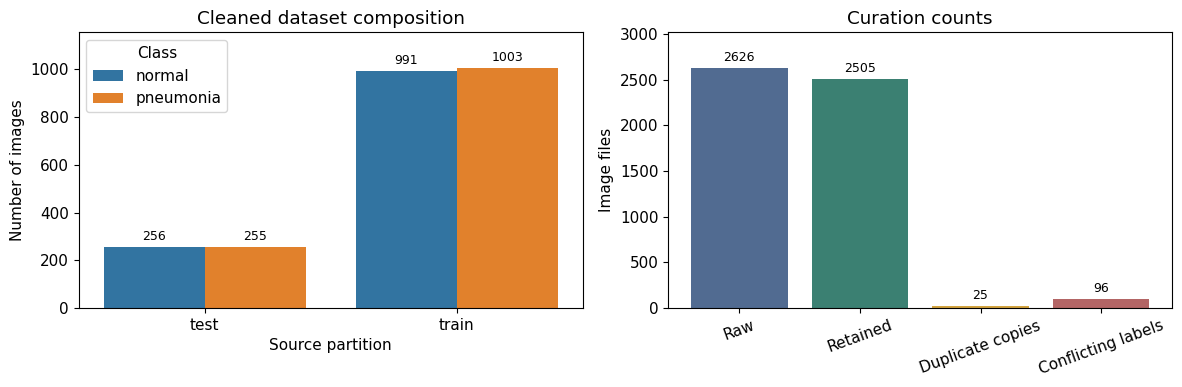

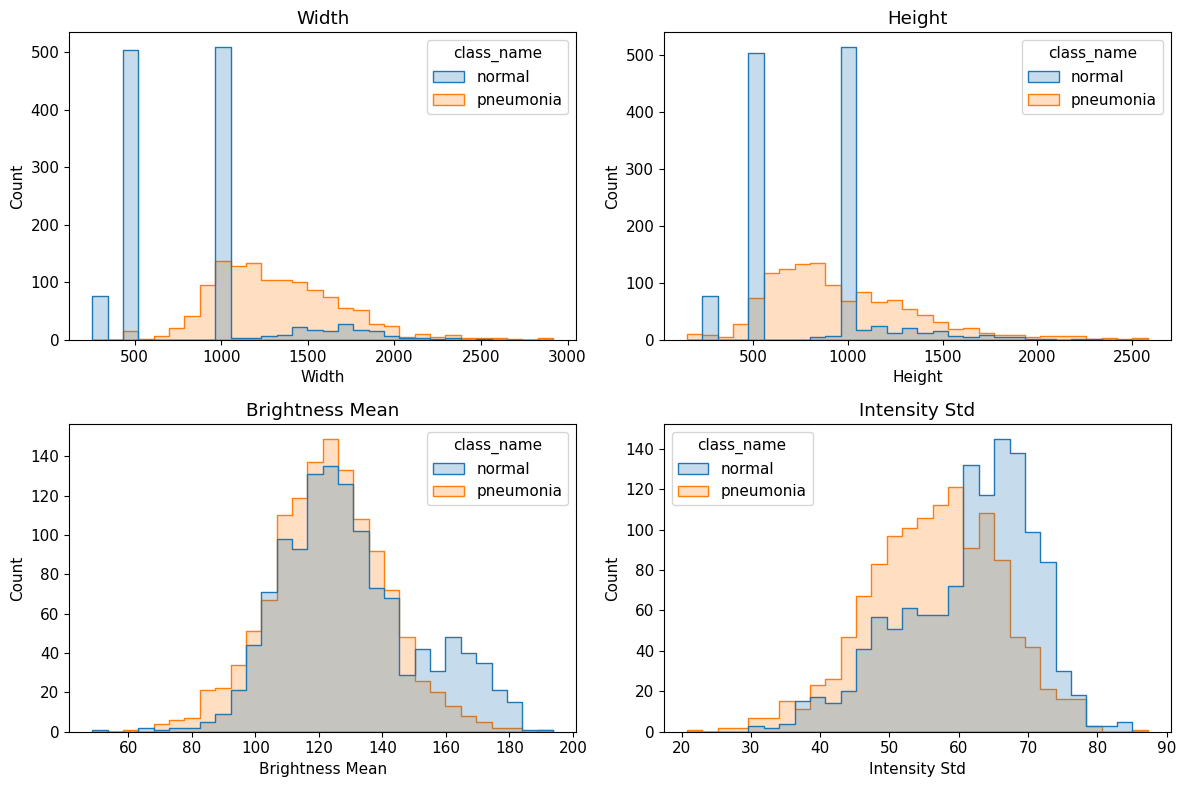

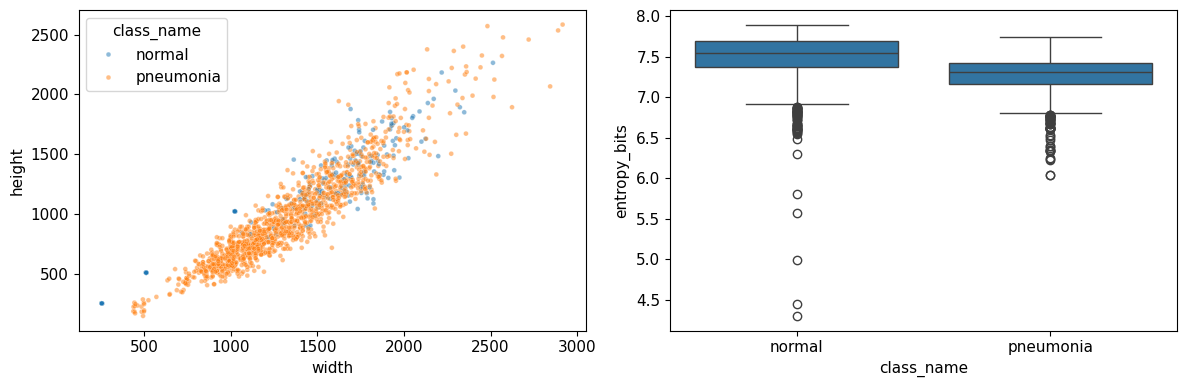

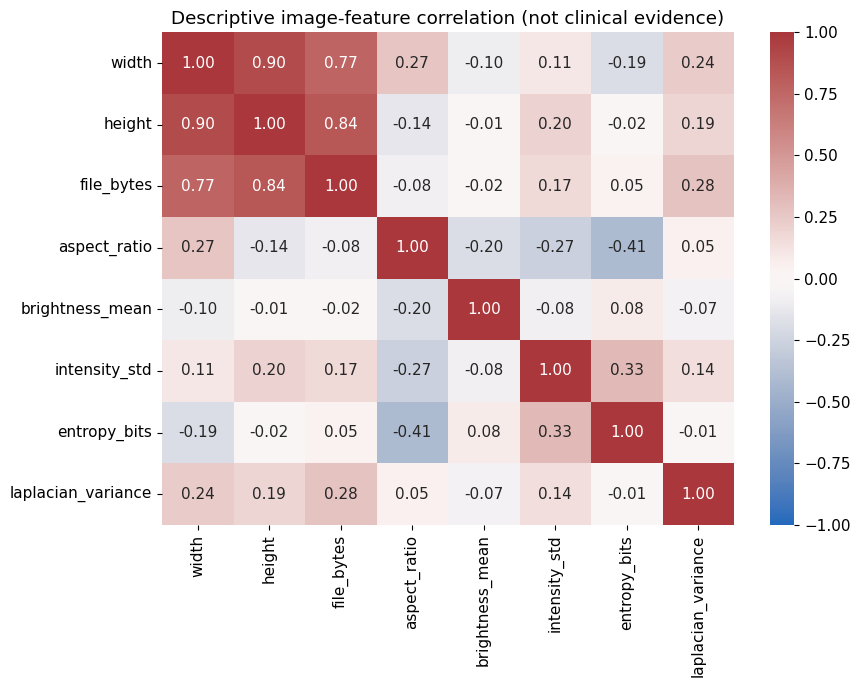

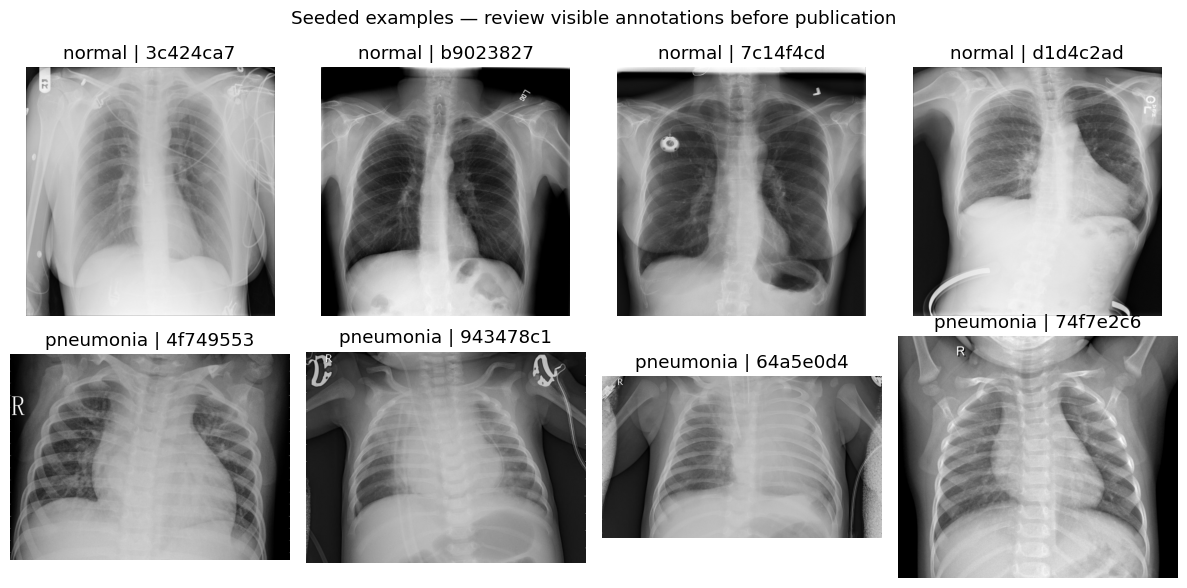

In [7]:
quality_rows = []
for row in tqdm(clean_manifest.itertuples(), total=len(clean_manifest), desc='Image descriptors'):
    with Image.open(RELEASE/row.path) as image:
        image = ImageOps.exif_transpose(image).convert('L')
        preview = image.resize((256,256), Image.Resampling.BILINEAR)
        a = np.asarray(preview, dtype=np.float32)
        hist = np.bincount(a.astype(np.uint8).ravel(), minlength=256).astype(float); hist /= hist.sum()
        entropy = float(-(hist[hist>0]*np.log2(hist[hist>0])).sum())
        quality_rows.append(dict(image_id=row.image_id, brightness_mean=float(a.mean()), intensity_std=float(a.std()),
            entropy_bits=entropy, laplacian_variance=float(laplace(a).var()),
            near_black_fraction=float((a<=5).mean()), near_white_fraction=float((a>=250).mean()),
            phash=str(imagehash.phash(image, hash_size=8)), aspect_ratio=row.width/row.height))
quality = clean_manifest.merge(pd.DataFrame(quality_rows), on='image_id', validate='one_to_one')
quality['flag_low_resolution'] = quality[['width','height']].min(axis=1) < 224
quality['flag_low_contrast'] = quality.intensity_std < 10
quality['flag_extreme_brightness'] = (quality.brightness_mean < 20) | (quality.brightness_mean > 235)
quality.to_csv(REPORTS/'image_descriptors.csv', index=False)
fields = ['width','height','file_bytes','aspect_ratio','brightness_mean','intensity_std','entropy_bits','laplacian_variance']
quality[fields].describe().T.to_csv(REPORTS/'descriptive_statistics.csv')
quality.groupby(['original_split','class_name'])[fields].agg(['mean','std','median']).to_csv(REPORTS/'statistics_by_split_and_class.csv')
quality.groupby('class_name')[fields].agg(['count','mean','std','min','median','max']).to_csv(REPORTS/'statistics_by_class.csv')
quality.isna().sum().rename('missing_count').to_csv(REPORTS/'manifest_missing_values.csv')
quality[['flag_low_resolution','flag_low_contrast','flag_extreme_brightness']].sum().rename('flagged_images').to_csv(REPORTS/'quality_flags.csv')
display(quality[fields].describe().T)

fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=composition, x='original_split', y='images', hue='class_name', ax=axes[0])
axes[0].set(title='Cleaned dataset composition',xlabel='Source partition',ylabel='Number of images')
axes[0].legend(title='Class')
for container in axes[0].containers: axes[0].bar_label(container,padding=3,fontsize=9)
axes[0].set_ylim(0,composition.images.max()*1.15)
axes[1].bar(['Raw','Retained','Duplicate copies','Conflicting labels'],
            [audit_summary[k] for k in ['raw_images','retained','duplicate_copies','conflicting_label_images']], color=['#516b91','#3b8072','#d3a440','#b36565'])
axes[1].tick_params(axis='x',rotation=20); axes[1].set_title('Curation counts'); axes[1].set_ylabel('Image files')
for container in axes[1].containers: axes[1].bar_label(container,padding=3,fontsize=9)
axes[1].set_ylim(0,audit_summary['raw_images']*1.15)
save_figure('01_composition_and_curation')
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,['width','height','brightness_mean','intensity_std']):
    sns.histplot(data=quality,x=col,hue='class_name',element='step',bins=30,ax=ax); ax.set_title(col.replace('_',' ').title()); ax.set_xlabel(col.replace('_',' ').title())
save_figure('02_image_distributions')
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.scatterplot(data=quality,x='width',y='height',hue='class_name',alpha=.5,s=12,ax=axes[0])
sns.boxplot(data=quality,x='class_name',y='entropy_bits',ax=axes[1])
save_figure('03_resolution_and_entropy')
plt.figure(figsize=(9,7)); sns.heatmap(quality[fields].corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1,vmax=1)
plt.title('Descriptive image-feature correlation (not clinical evidence)'); save_figure('04_descriptor_correlations')
fig,axes=plt.subplots(2,4,figsize=(12,6))
for i,label in enumerate(['normal','pneumonia']):
    samples=quality[quality.class_name==label].sample(n=min(4,sum(quality.class_name==label)),random_state=42)
    for ax, row in zip(axes[i], samples.itertuples()):
        with Image.open(RELEASE/row.path) as im: ax.imshow(ImageOps.exif_transpose(im).convert('L'),cmap='gray')
        ax.set_title(label+' | '+row.image_id[:8]); ax.axis('off')
plt.suptitle('Seeded examples — review visible annotations before publication'); save_figure('05_sample_images')

## 6. Near-duplicate review candidates (no automatic removal)
Compare 64-bit perceptual hashes of retained images. Pairs at Hamming distance ≤4 are saved for manual review, with cross-split pairs marked. Anatomically similar but distinct images may match; this is not a patient-identity test. If manual review changes the release, rerun the benchmark on that revised, locked release and report new counts.

In [8]:
pair_columns = ['image_id_a','image_id_b','class_a','class_b','split_a','split_b','phash_distance','cross_split','label_disagreement']
pairs=[]
if RUN_NEAR_DUPLICATE_REVIEW:
    rows=list(quality.itertuples()); hashes=[int(r.phash,16) for r in rows]
    for i in tqdm(range(len(rows)),desc='Perceptual-hash review'):
        for j in range(i+1,len(rows)):
            distance=(hashes[i]^hashes[j]).bit_count()
            if distance <= PHASH_MAX_DISTANCE:
                a,b=rows[i],rows[j]
                pairs.append([a.image_id,b.image_id,a.class_name,b.class_name,a.original_split,b.original_split,
                              distance,a.original_split!=b.original_split,a.class_name!=b.class_name])
near_pairs=pd.DataFrame(pairs,columns=pair_columns)
near_pairs.to_csv(REPORTS/'near_duplicate_candidates_REVIEW_ONLY.csv',index=False)
print('Candidate pairs:',len(near_pairs),'| Cross-split:',int(near_pairs.cross_split.sum()) if len(near_pairs) else 0)
print('These candidates are NOT deleted; exact audit counts remain unchanged.')

Perceptual-hash review:   0%|          | 0/2505 [00:00<?, ?it/s]

Candidate pairs: 115 | Cross-split: 41
These candidates are NOT deleted; exact audit counts remain unchanged.


## 7. Fixed benchmark split and data dictionary
The exported dataset retains its original train/test folders. Benchmarks use 80%/20% stratification inside the cleaned training subset with seed 42, leaving the original cleaned test subset held out. These are image-level partitions: no patient identifiers are available to establish patient independence. A separate split manifest documents every assignment.

In [9]:
from sklearn.model_selection import train_test_split
training_pool=clean_manifest[clean_manifest.original_split=='train'].copy()
test_frame=clean_manifest[clean_manifest.original_split=='test'].copy()
train_frame,val_frame=train_test_split(training_pool,test_size=VALIDATION_FRACTION,random_state=SPLIT_SEED,stratify=training_pool.class_name)
for frame,role in [(train_frame,'train'),(val_frame,'validation'),(test_frame,'test')]: frame['benchmark_split']=role
benchmark_manifest=pd.concat([train_frame,val_frame,test_frame],ignore_index=True)
assert benchmark_manifest.image_id.is_unique
assert len(benchmark_manifest)==len(clean_manifest)
benchmark_manifest.to_csv(REPORTS/'benchmark_splits.csv',index=False)
benchmark_manifest.to_csv(RELEASE/'benchmark_splits.csv',index=False)
class_to_idx={'normal':0,'pneumonia':1}
atomic_json(REPORTS/'class_mapping.json',class_to_idx)
display(pd.crosstab(benchmark_manifest.benchmark_split,benchmark_manifest.class_name))

descriptions={
'image_id':'SHA-256 of EXIF-oriented RGB dimensions and pixels; image identifier, NOT patient ID.',
'path':'Relative file path inside the cleaned release.', 'class_name':'Source class folder label; not independently clinically adjudicated.',
'original_split':'Original source partition: train or test.', 'width':'EXIF-oriented width in native pixels.',
'height':'EXIF-oriented height in native pixels.', 'source_format':'Original Pillow-decoded image format.',
'file_bytes':'Original file size in bytes.', 'file_sha256':'SHA-256 of original retained file bytes.',
'pixel_sha256':'Same decoded-image hash used for exact deduplication.',
'source_relative_path':'Provenance path within extracted version-5 source archive.',
'benchmark_split':'Fixed image-level train/validation/test assignment for benchmarks.'}
dictionary=pd.DataFrame([{'field':c,'dtype':str(benchmark_manifest[c].dtype),'description':descriptions.get(c,'See methodology.'),
                         'missing_count':int(benchmark_manifest[c].isna().sum())} for c in benchmark_manifest.columns])
dictionary.to_csv(RELEASE/'data_dictionary.csv',index=False)
dictionary.to_csv(REPORTS/'data_dictionary.csv',index=False)

class_name,normal,pneumonia
benchmark_split,,
test,256,255
train,793,802
validation,198,201


## 8. Release documentation and downloadable version-6 candidate
This creates the cleaned dataset export before model training. The release includes an audit, manifests, checksums, a change log and a data card. Source licensing is recorded as CC BY 4.0 with attribution; authors must confirm collection rights and the release text. Original excluded/conflicting image files are not included in the cleaned ZIP.

In [10]:
authors='MD IRFANUL KABIR HIRA; MST MORIOM AKTER BITHEE; Shafee Ahmed; Laboni Akter; Mst.Jannatul Mawa Anonna'
card=dict(title='A Primary Chest X-ray Dataset of Normal Bangladesh — cleaned release candidate',
          release_status='Version 6 candidate; NOT published by this notebook',source_doi=SOURCE_DOI,source_url=SOURCE_URL,
          source_authors=authors,source_license='CC BY 4.0',source_archive_sha256=source_hash,
          observed_counts=audit_summary,class_mapping=class_to_idx,
          near_duplicate_candidate_pairs=int(len(near_pairs)),
          near_duplicate_cross_split_pairs=int(near_pairs.cross_split.sum()) if len(near_pairs) else 0,
          original_splits_preserved=True,patient_ids_available=False,
          collection_location='Epic Chittagong, Bangladesh (as described by source repository)',
          ethics_approval='AUTHOR TO CONFIRM',consent_or_waiver='AUTHOR TO CONFIRM',
          acquisition_device_and_protocol='AUTHOR TO CONFIRM',label_assignment_and_review='AUTHOR TO CONFIRM',
          identifier_removal_and_burned_in_text_review='AUTHOR TO CONFIRM',
          new_version_doi='PENDING: insert the DOI assigned after repository publication',
          preprocessing='None in release: original bytes/resolution preserved; see benchmark protocol for model transforms.')
atomic_json(RELEASE/'dataset_card.json',card)
for name in ['source_files.json','cleaning_summary.json','source_inventory_and_decisions.csv','removed_duplicate_copies.csv',
             'excluded_conflicting_labels.csv','unreadable_images.csv','expected_vs_observed.csv','clean_composition.csv',
             'near_duplicate_candidates_REVIEW_ONLY.csv']:
    shutil.copyfile(REPORTS/name,RELEASE/name)
readme=f"""# Chest X-ray Bangladesh — cleaned release candidate
Source: {SOURCE_URL}\nSource DOI: {SOURCE_DOI}\nAttribution: {authors}\nSource license: CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/).
This derivative removes duplicate copies and excludes conflicting-label groups; images are otherwise unchanged.

## Counts and curation
Observed source images: {audit_summary['raw_images']}; retained: {audit_summary['retained']}.
Removed redundant same-label copies: {audit_summary['duplicate_copies']}.
Excluded images in conflicting-label groups: {audit_summary['conflicting_label_images']}.
Unreadable files: {audit_summary['unreadable']}.
SHA-256 grouping uses EXIF-oriented RGB dimensions+pixels. Conflict exclusion precedes duplicate removal.
Same-label groups retain the test copy first, then the lexically first path. Labels are not adjudicated or corrected.

## Files
images/train/normal/, images/train/pneumonia/, images/test/normal/, images/test/pneumonia/: original retained images.
manifest.csv: one row per image, relative paths and hashes. data_dictionary.csv: field descriptions.
benchmark_splits.csv: benchmark-only validation carve-out; physical source split folders remain unchanged.
source_inventory_and_decisions.csv: all source files and cleaning decisions; excluded images themselves are absent.
Other audit CSV/JSON files contain exclusion lists, count verification, source file metadata and composition.
near_duplicate_candidates_REVIEW_ONLY.csv: perceptual-hash review candidates; no automatic deletion.
dataset_card.json: provenance and author-completion fields. CHANGELOG.md: changes from v5.
SHA256SUMS.txt: integrity hashes for files in this package except the checksum list itself.

## Use and limitations
normal=0, pneumonia=1. Clinical labels originate from source folders, without independent adjudication here.
No patient metadata/group identifiers are provided; image-level split independence does not imply patient independence.
Exact deduplication does not remove every crop, recompression or repeat examination.
Images preserve source bytes, embedded metadata and visible annotations: author privacy review remains necessary.
No augmentation or synthetic images are exported. Do not interpret the release as clinically validated.
Confirm patient consent/waiver, institutional approval, acquisition devices, selection criteria and label-review procedure.
Resolve those fields before claiming a publication-ready release. Do not invent approval IDs or clinical provenance.

## Publication
This folder is a version-6 CANDIDATE. The notebook does not upload to Mendeley or SSRN.
After reviewing it, upload the ZIP as the next version of your existing repository record.
Use the actual new DOI assigned by Mendeley in the manuscript; retain the v5 DOI as source provenance.
Include this notebook as accompanying analysis code when uploading the release.
"""
(RELEASE/'README.md').write_text(readme,encoding='utf-8')
(RELEASE/'CHANGELOG.md').write_text(f"""# Change log: source v5 to v6 candidate
- Source archive SHA-256: {source_hash}
- Excluded {audit_summary['conflicting_label_images']} files with conflicting labels for identical decoded content.
- Removed {audit_summary['duplicate_copies']} redundant same-label copies.
- Retained {audit_summary['retained']} images under content-hash filenames with unchanged bytes.
- Preserved train/test membership for retained images; added audit and benchmark split manifests.
- Added provenance, checksums, data dictionary and limitations. No clinical relabeling was performed.
""")
checksums=[sha256_file(p)+'  '+p.relative_to(RELEASE).as_posix() for p in sorted(RELEASE.rglob('*')) if p.is_file() and p.name!='SHA256SUMS.txt']
(RELEASE/'SHA256SUMS.txt').write_text('\n'.join(checksums)+'\n')
release_zip=EXPORTS/'Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE.zip'
if EXPORT_CLEAN_DATASET:
    with zipfile.ZipFile(release_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=1) as z:
        for p in sorted(RELEASE.rglob('*')):
            if p.is_file(): z.write(p,arcname=RELEASE.name+'/'+p.relative_to(RELEASE).as_posix())
    with zipfile.ZipFile(release_zip) as z:
        bad=z.testzip()
        if bad: raise RuntimeError('ZIP integrity failed: '+bad)
        image_members=[p for p in z.namelist() if '/images/' in p and not p.endswith('/')]
        assert len(image_members)==audit_summary['retained']
    atomic_json(EXPORTS/'release_zip_checksum.json',{'filename':release_zip.name,'sha256':sha256_file(release_zip),'images':len(image_members)})
    print('Cleaned release ready:',release_zip,'| MB:',round(release_zip.stat().st_size/1e6,1))
    display(FileLink(str(release_zip)))
else: print('Dataset ZIP export disabled; set EXPORT_CLEAN_DATASET=True to create it.')

Cleaned release ready: /kaggle/working/chest_xray_dataset_v6/exports/Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE.zip | MB: 469.0


/kaggle/working/chest_xray_dataset_v6/exports/Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE.zip

## 9. Reproducible benchmark protocol
**Models:** ImageNet-pretrained ResNet18, ResNet50, DenseNet121, EfficientNet-B0 and MobileNetV3-Large. Model weights use explicit V1 variants. All are fine-tuned end-to-end with the same fixed data split, optimizer (AdamW), batch size, 12-epoch budget and common 224×224 preprocessing. This common protocol is not individually optimized for each architecture.

Preprocessing: EXIF orientation → RGB → aspect-preserving resize with black padding → ImageNet normalization. Training uses small random rotations (±5°); evaluation has no random transform. Native release images remain unchanged. No test-based hyperparameter tuning, oversampling or synthetic data. Best checkpoint uses **validation macro-F1**, then lower validation loss to break ties. Test metrics use argmax (two-class threshold 0.5). Positive class is **pneumonia**.

Default: 5 models × 3 seeds = 15 runs (180 epochs). Run time depends on your accelerator. Set RUN_BENCHMARKS=False for curation/EDA/export only. Completed runs resume using a fingerprint of configuration, split and runner code; an interrupted individual run restarts. Models are trained sequentially on one GPU. No fabricated results or guaranteed high scores.

Metrics: accuracy, macro precision/recall/F1, balanced accuracy, pneumonia sensitivity, normal specificity, pneumonia ROC-AUC and average precision, Brier score, 15-bin expected calibration error, parameters and training time. Seed SD describes optimization variability on a fixed split, not a population confidence interval. A majority-class baseline provides context.

In [11]:
import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve)

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if RUN_BENCHMARKS and DEVICE.type!='cuda':
    raise RuntimeError('Enable a Kaggle GPU, or set RUN_BENCHMARKS=False to export without training.')
MODEL_SPECS={
 'resnet18':(models.resnet18,models.ResNet18_Weights.IMAGENET1K_V1),
 'resnet50':(models.resnet50,models.ResNet50_Weights.IMAGENET1K_V1),
 'densenet121':(models.densenet121,models.DenseNet121_Weights.IMAGENET1K_V1),
 'efficientnet_b0':(models.efficientnet_b0,models.EfficientNet_B0_Weights.IMAGENET1K_V1),
 'mobilenet_v3_large':(models.mobilenet_v3_large,models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)}
assert len(BENCHMARK_SEEDS)==len(set(BENCHMARK_SEEDS)) and BENCHMARK_SEEDS
assert len(BENCHMARK_MODELS)==len(set(BENCHMARK_MODELS)) and set(BENCHMARK_MODELS)<=set(MODEL_SPECS)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False

def seed_worker(worker_id):
    seed=torch.initial_seed() % 2**32; random.seed(seed); np.random.seed(seed)

class XrayData(Dataset):
    def __init__(self,frame,training=False):
        self.frame=frame.reset_index(drop=True); self.training=training
        self.rotate=transforms.RandomRotation(5,interpolation=transforms.InterpolationMode.BILINEAR,fill=0)
        self.normalize=transforms.Compose([transforms.ToTensor(), transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    def __len__(self):return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        with Image.open(RELEASE/row.path) as im: im=ImageOps.exif_transpose(im).convert('RGB')
        im=ImageOps.pad(im,(IMAGE_SIZE,IMAGE_SIZE),method=Image.Resampling.BILINEAR,color=(0,0,0))
        if self.training:im=self.rotate(im)
        return self.normalize(im),class_to_idx[row.class_name]

def make_loader(frame,training,seed):
    return DataLoader(XrayData(frame,training),batch_size=BATCH_SIZE,shuffle=training,
                      num_workers=NUM_WORKERS,pin_memory=DEVICE.type=='cuda',worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(seed))

def build_model(name):
    constructor,weights=MODEL_SPECS[name]; net=constructor(weights=weights if PRETRAINED else None)
    if name.startswith('resnet'):net.fc=nn.Linear(net.fc.in_features,2)
    elif name.startswith('densenet'):net.classifier=nn.Linear(net.classifier.in_features,2)
    else:net.classifier[-1]=nn.Linear(net.classifier[-1].in_features,2)
    return net.to(DEVICE)

def compute_metrics(y,probabilities):
    y=np.asarray(y,dtype=int); probabilities=np.asarray(probabilities,dtype=float)
    if probabilities.shape!=(len(y),2) or not np.isfinite(probabilities).all():raise ValueError('Invalid probabilities.')
    pred=probabilities.argmax(1); p,r,f,_=precision_recall_fscore_support(y,pred,labels=[0,1],average='macro',zero_division=0)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    conf=probabilities.max(1); correct=(pred==y); ece=0.0
    for lower,upper in zip(np.linspace(0,1,16)[:-1],np.linspace(0,1,16)[1:]):
        mask=(conf>lower)&(conf<=upper)
        if mask.any():ece+=mask.mean()*abs(correct[mask].mean()-conf[mask].mean())
    both=len(np.unique(y))==2
    return dict(accuracy=float(accuracy_score(y,pred)),precision_macro=float(p),recall_macro=float(r),f1_macro=float(f),
                balanced_accuracy=float(balanced_accuracy_score(y,pred)),sensitivity=float(tp/(tp+fn)) if tp+fn else 0.,
                specificity=float(tn/(tn+fp)) if tn+fp else 0.,roc_auc=float(roc_auc_score(y,probabilities[:,1])) if both else None,
                average_precision=float(average_precision_score(y,probabilities[:,1])) if both else None,
                brier=float(brier_score_loss(y,probabilities[:,1])),ece15=float(ece))

@torch.no_grad()
def evaluate_model(net,loader):
    net.eval(); targets=[]; probabilities=[]; loss_sum=0.; total=0
    for images,labels in loader:
        images,labels=images.to(DEVICE),labels.to(DEVICE); outputs=net(images)
        loss_sum+=nn.functional.cross_entropy(outputs,labels).item()*len(labels);total+=len(labels)
        targets.extend(labels.cpu().tolist()); probabilities.extend(outputs.softmax(1).cpu().tolist())
    return loss_sum/total,np.array(targets),np.array(probabilities)

def train_epoch(net,loader,opt):
    net.train();total=0;loss_sum=0.
    for images,labels in tqdm(loader,desc='Train',leave=False):
        images,labels=images.to(DEVICE),labels.to(DEVICE);opt.zero_grad(set_to_none=True)
        loss=nn.functional.cross_entropy(net(images),labels)
        if not torch.isfinite(loss):raise RuntimeError('Non-finite training loss.')
        loss.backward();opt.step();loss_sum+=loss.item()*len(labels);total+=len(labels)
    return loss_sum/total

print('Device:',DEVICE,'| torch:',torch.__version__,'| torchvision:',torchvision.__version__)

Device: cuda | torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128


## 10. Run all models and save auditable predictions
The run fingerprint separates changed protocols. Training histories, selected epoch, probabilities and confusion matrices are saved per model/seed. Completed results are reused only inside the matching fingerprint directory. GPU out-of-memory: reduce BATCH_SIZE to 8 and rerun (this creates a new protocol).

In [12]:
BENCHMARKS=ROOT/'benchmarks'
def benchmark_one(name,seed,study):
    destination=study/name/f'seed_{seed}';destination.mkdir(parents=True,exist_ok=True)
    completed=destination/'metrics.json'
    if completed.exists():print('Reuse completed:',name,seed);return json.loads(completed.read_text())
    seed_everything(seed);net=build_model(name)
    train_loader=make_loader(train_frame,True,seed);val_loader=make_loader(val_frame,False,seed);test_loader=make_loader(test_frame,False,seed)
    opt=torch.optim.AdamW(net.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=EPOCHS)
    history=[];best_key=(-1.,float('-inf'));best_epoch=None;checkpoint=destination/'best.pth'
    if DEVICE.type=='cuda':torch.cuda.synchronize()
    started=time.perf_counter()
    for epoch in range(EPOCHS):
        train_loss=train_epoch(net,train_loader,opt)
        val_loss,y_val,p_val=evaluate_model(net,val_loader); vm=compute_metrics(y_val,p_val)
        history.append(dict(epoch=epoch+1,train_loss=train_loss,val_loss=val_loss,val_macro_f1=vm['f1_macro'],val_accuracy=vm['accuracy'],learning_rate=opt.param_groups[0]['lr']))
        key=(vm['f1_macro'],-val_loss)
        if key>best_key:best_key=key;best_epoch=epoch+1;torch.save(net.state_dict(),checkpoint)
        scheduler.step();pd.DataFrame(history).to_csv(destination/'history.csv',index=False)
        print(f'{name} seed {seed}, epoch {epoch+1}/{EPOCHS}: validation macro-F1={vm["f1_macro"]:.4f}')
    if DEVICE.type=='cuda':torch.cuda.synchronize()
    training_seconds=time.perf_counter()-started
    net.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=True))
    test_loss,y,probs=evaluate_model(net,test_loader)
    predictions=test_frame.reset_index(drop=True)[['image_id','path','class_name']].copy()
    predictions['true_label']=y;predictions['predicted_label']=probs.argmax(1)
    predictions['probability_normal']=probs[:,0];predictions['probability_pneumonia']=probs[:,1]
    predictions.to_csv(destination/'predictions.csv',index=False)
    cm=confusion_matrix(y,probs.argmax(1),labels=[0,1]);pd.DataFrame(cm,index=['normal','pneumonia'],columns=['normal','pneumonia']).to_csv(destination/'confusion_matrix.csv')
    result=dict(model=name,seed=seed,selected_epoch=best_epoch,validation_macro_f1=best_key[0],test_loss=test_loss,
                parameters=sum(p.numel() for p in net.parameters()),training_seconds=training_seconds,**compute_metrics(y,probs))
    if not KEEP_CHECKPOINTS:checkpoint.unlink(missing_ok=True)
    atomic_json(completed,result)
    del net,opt,scheduler,train_loader,val_loader,test_loader;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return result

ordered_split=benchmark_manifest[['image_id','class_name','benchmark_split']].values.tolist()
runner_source='\n'.join(inspect.getsource(f) for f in [seed_everything,seed_worker,XrayData.__init__,XrayData.__getitem__,make_loader,build_model,compute_metrics,evaluate_model,train_epoch,benchmark_one])
protocol=dict(source_doi=SOURCE_DOI,source_sha256=source_hash,models=BENCHMARK_MODELS,seeds=BENCHMARK_SEEDS,
              weights='IMAGENET1K_V1' if PRETRAINED else None,epochs=EPOCHS,batch_size=BATCH_SIZE,
              image_size=IMAGE_SIZE,learning_rate=LEARNING_RATE,weight_decay=WEIGHT_DECAY,
              optimizer='AdamW',scheduler='CosineAnnealingLR',selection='validation macro-F1, then lower loss',
              split_seed=SPLIT_SEED,ordered_split=ordered_split,torch_version=str(torch.__version__),
              torchvision_version=str(torchvision.__version__),numpy_version=np.__version__,keep_checkpoints=KEEP_CHECKPOINTS,num_workers=NUM_WORKERS,
              gpu_name=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU',
              runner_sha256=hashlib.sha256(runner_source.encode()).hexdigest())
study_id=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:16]
STUDY=BENCHMARKS/study_id;STUDY.mkdir(parents=True,exist_ok=True);atomic_json(STUDY/'protocol.json',protocol)
benchmark_results=[]
if RUN_BENCHMARKS:
    for name in BENCHMARK_MODELS:
        for seed in BENCHMARK_SEEDS:
            benchmark_results.append(benchmark_one(name,seed,STUDY))
            pd.DataFrame(benchmark_results).to_csv(STUDY/'per_seed_results.csv',index=False)
else:print('Benchmark training skipped by configuration.')
# A train-derived majority-class predictor, without looking at the test labels to fit it.
majority=class_to_idx[train_frame.class_name.value_counts().idxmax()]
y_dummy=test_frame.class_name.map(class_to_idx).to_numpy();p_dummy=np.zeros((len(y_dummy),2));p_dummy[:,majority]=1
atomic_json(REPORTS/'majority_baseline.json',compute_metrics(y_dummy,p_dummy))
print('Majority-class baseline:',compute_metrics(y_dummy,p_dummy))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


Train:   0%|          | 0/100 [00:00<?, ?it/s]

resnet18 seed 42, epoch 1/12: validation macro-F1=0.9446


Train:   0%|          | 0/100 [00:00<?, ?it/s]

...

Train:   0%|          | 0/100 [00:00<?, ?it/s]

mobilenet_v3_large seed 44, epoch 11/12: validation macro-F1=0.9148


Train:   0%|          | 0/100 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e23b1752b60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e23b1752b60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

mobilenet_v3_large seed 44, epoch 12/12: validation macro-F1=0.9173
Majority-class baseline: {'accuracy': 0.49902152641878667, 'precision_macro': 0.24951076320939333, 'recall_macro': 0.5, 'f1_macro': 0.3328981723237598, 'balanced_accuracy': 0.5, 'sensitivity': 1.0, 'specificity': 0.0, 'roc_auc': 0.5, 'average_precision': 0.49902152641878667, 'brier': 0.5009784735812133, 'ece15': 0.5009784735812133}


## 11. Benchmark tables and figures
Main table: accuracy (%) and macro precision/recall/F1, mean ± sample SD. Extended metrics are saved separately. ROC/PR/confusion figures use the first predeclared seed (not the best test seed). No table is generated if the benchmark suite is incomplete. Single-seed runs report a value with “SD unavailable”, not zero uncertainty.

,Model,Accuracy (%),Precision,Recall,F1-score,ROC-AUC
0,resnet18,92.30 ± 0.63,0.9281 ± 0.0103,0.9231 ± 0.0063,0.9228 ± 0.0061,0.9733 ± 0.0008
1,resnet50,91.65 ± 0.92,0.9193 ± 0.0120,0.9166 ± 0.0093,0.9164 ± 0.0091,0.9725 ± 0.0039
2,densenet121,92.50 ± 0.60,0.9292 ± 0.0073,0.9251 ± 0.0060,0.9248 ± 0.0060,0.9774 ± 0.0008
3,efficientnet_b0,92.50 ± 0.63,0.9309 ± 0.0081,0.9251 ± 0.0063,0.9247 ± 0.0062,0.9734 ± 0.0016
4,mobilenet_v3_large,92.37 ± 0.39,0.9317 ± 0.0045,0.9238 ± 0.0039,0.9233 ± 0.0039,0.9688 ± 0.0027


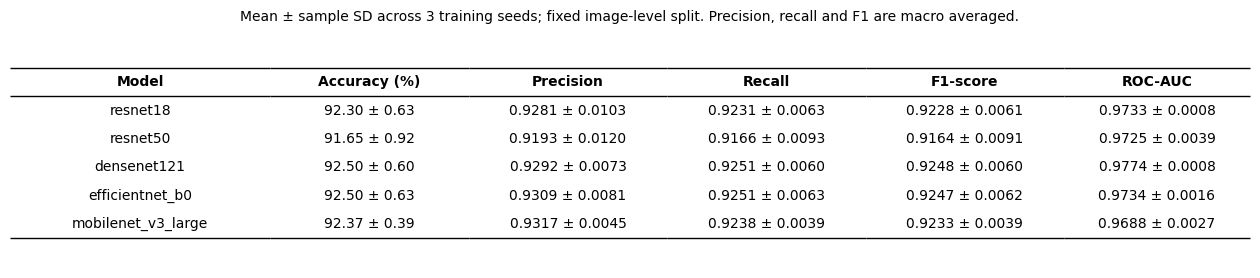

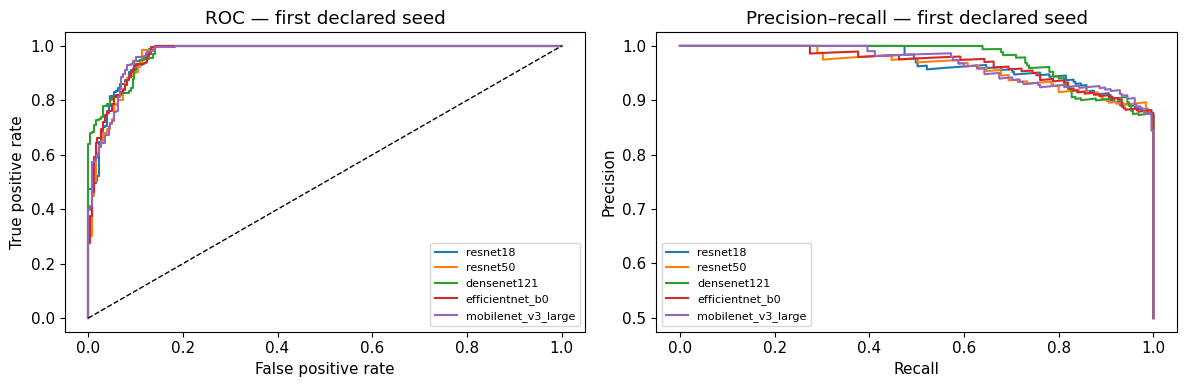

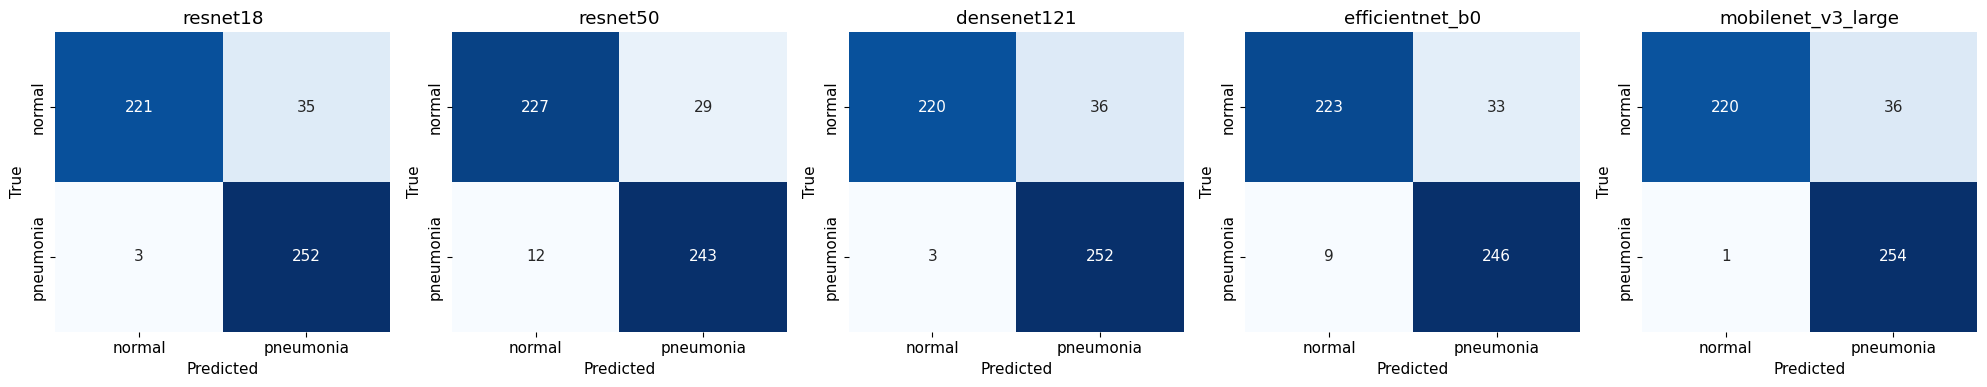

In [15]:
def save_benchmark_figure(name):
    plt.tight_layout(); plt.savefig(STUDY/(name+'.png'),dpi=300,bbox_inches='tight')
    plt.savefig(STUDY/(name+'.pdf'),bbox_inches='tight'); plt.show(); plt.close()

metric_names=['accuracy','precision_macro','recall_macro','f1_macro','balanced_accuracy','sensitivity','specificity','roc_auc','average_precision','brier','ece15','training_seconds']
if RUN_BENCHMARKS:
    results=pd.DataFrame(benchmark_results)
    expected={(m,s) for m in BENCHMARK_MODELS for s in BENCHMARK_SEEDS}
    assert set(zip(results.model,results.seed))==expected and not results.duplicated(['model','seed']).any()
    numeric=results.groupby('model')[metric_names].agg(['mean','std','count']).reindex(BENCHMARK_MODELS)
    numeric.to_csv(STUDY/'benchmark_summary_numeric.csv')
    table_rows=[]
    for name in BENCHMARK_MODELS:
        row={'Model':name}
        for metric,label in [('accuracy','Accuracy (%)'),('precision_macro','Precision'),('recall_macro','Recall'),('f1_macro','F1-score'),('roc_auc','ROC-AUC')]:
            values=results.loc[results.model==name,metric]*(100 if metric=='accuracy' else 1)
            digits=2 if metric=='accuracy' else 4
            row[label]=(f'{values.mean():.{digits}f} ± {values.std(ddof=1):.{digits}f}' if len(values)>1 else f'{values.mean():.{digits}f} (SD unavailable)')
        table_rows.append(row)
    table=pd.DataFrame(table_rows);table.to_csv(STUDY/'benchmark_table.csv',index=False)
    caption=f'Mean ± sample SD across {len(BENCHMARK_SEEDS)} training seeds; fixed image-level split. Precision, recall and F1 are macro averaged.'
    display(table)
    (STUDY/'benchmark_table.html').write_text('<p>'+caption+'</p>'+table.to_html(index=False))
    # Pandas produces booktabs commands; add \\usepackage{booktabs} to your manuscript.
    (STUDY/'benchmark_table.tex').write_text(table.to_latex(index=False,escape=True,caption=caption,label='tab:chest_benchmarks').replace('±',r'$\pm$'))
    fig,ax=plt.subplots(figsize=(16,3));ax.axis('off')
    artist=ax.table(cellText=table.values,colLabels=table.columns,cellLoc='center',loc='center',colWidths=[.21,.16,.16,.16,.16,.15])
    artist.auto_set_font_size(False);artist.set_fontsize(10);artist.scale(1,1.7)
    for (r,c),cell in artist.get_celld().items():
        cell.visible_edges='';cell.set_facecolor('white')
        if r==0:cell.visible_edges='TB';cell.set_text_props(weight='bold')
        if r==len(table):cell.visible_edges='B'
    ax.set_title(caption,fontsize=10,pad=12)
    fig.savefig(STUDY/'benchmark_table.png',dpi=400,bbox_inches='tight');fig.savefig(STUDY/'benchmark_table.pdf',bbox_inches='tight');plt.show();plt.close()
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in BENCHMARK_MODELS:
        pred=pd.read_csv(STUDY/name/f'seed_{BENCHMARK_SEEDS[0]}'/'predictions.csv')
        fpr,tpr,_=roc_curve(pred.true_label,pred.probability_pneumonia)
        pr,re,_=precision_recall_curve(pred.true_label,pred.probability_pneumonia)
        axes[0].plot(fpr,tpr,label=name);axes[1].plot(re,pr,label=name)
    axes[0].plot([0,1],[0,1],'k--',linewidth=1);axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC — first declared seed')
    axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall — first declared seed')
    for ax in axes:ax.legend(fontsize=8)
    save_benchmark_figure('06_benchmark_roc_pr')
    fig,axes=plt.subplots(1,len(BENCHMARK_MODELS),figsize=(4*len(BENCHMARK_MODELS),4),squeeze=False)
    for ax,name in zip(axes[0],BENCHMARK_MODELS):
        cm=pd.read_csv(STUDY/name/f'seed_{BENCHMARK_SEEDS[0]}'/'confusion_matrix.csv',index_col=0)
        sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax);ax.set(title=name,xlabel='Predicted',ylabel='True')
    save_benchmark_figure('07_benchmark_confusion_matrices')
else:print('No benchmark table: training disabled. No placeholder performance is inserted.')

## 12. Data in Brief–style manuscript support and final export
Produces factual source notes, a specifications table, value-of-data bullets, methods and limitations aligned with the attached template. Unknown clinical/collection details remain explicit author-completion fields. These files support manuscript preparation; they are not a completed ethics statement or a finished preprint. No clinical superiority or “high quality” conclusion is inferred from accuracy.

Download the dataset ZIP and manuscript-support ZIP from the Kaggle Output panel, then review and upload them yourself. The support ZIP excludes the raw/clean image directories and checkpoint files; the separate cleaned dataset ZIP contains the images.

In [16]:
specifications=pd.DataFrame([
 ('Subject','Medical imaging / computer vision'),
 ('Specific subject area','Chest radiograph dataset curation and reproducible image-classification benchmarks'),
 ('Type of data','Native image files; curated image subset; CSV manifests/statistics; PNG/PDF figures; JSON provenance'),
 ('Data collection','Source repository reports Epic Chittagong, Bangladesh. Device, inclusion criteria, collection dates, patient counts and label adjudication: AUTHOR TO CONFIRM.'),
 ('Data source location','Epic Chittagong, Bangladesh (source-reported)'),
 ('Data accessibility',f'Mendeley Data source v5: {SOURCE_DOI}; {SOURCE_URL}. Cleaned version DOI: PENDING PUBLICATION.'),
 ('Related research article','AUTHOR TO CONFIRM, or state none if applicable')],columns=['Field','Content'])
specifications.to_csv(REPORTS/'specifications_table.csv',index=False)
notes=f"""# Dataset manuscript evidence notes — Data in Brief structure
## Article information
Suggested descriptive title: A curated chest X-ray dataset from Bangladesh for normal and pneumonia image classification.
Author list, affiliations, corresponding author: confirm author-provided details; source contributors are in dataset_card.json.
Suggested keywords: radiography; medical imaging; image curation; duplicate detection; reproducibility; transfer learning.
The attached template requests a 100–500 word abstract, 3–6 value bullets, background and limitations each at most 200 words, and at most 20 references. This file is supporting material, not the finished article.

## Abstract facts (assemble after author verification)
Source DOI {SOURCE_DOI}. Audited {audit_summary['raw_images']} images; retained {audit_summary['retained']} after removing {audit_summary['duplicate_copies']} redundant copies and excluding {audit_summary['conflicting_label_images']} conflicting-label images; {audit_summary['unreadable']} unreadable files.
Native bytes/resolution retained. Repository source prose states 3,355 images; that differs from the verified ZIP, so report computed counts and disclose this discrepancy.
Benchmark completion in this execution: {'enabled; see per-seed tables' if RUN_BENCHMARKS else 'disabled; do not claim benchmark results'}.

## Value of the data (descriptive starting points)
- Provides a traceable curated subset of a public chest-radiograph collection from Bangladesh.
- Supplies file-level and decoded-pixel hashes and a complete inclusion/exclusion audit for reuse.
- Retains native image files and the surviving original train/test membership.
- Supplies fixed benchmark partitions, model settings and prediction-level outputs when benchmarks run.

## Background
AUTHOR TO COMPLETE: motivation for original collection and intended research reuse, without asserting unmeasured representativeness or clinical performance.

## Data description
Use README.md for every exported directory/file. Use clean_composition.csv, manifest.csv, data_dictionary.csv and figures 01–05 for image counts, resolution, descriptive intensity properties and examples.
Statistics are image-level, not patient-level. Perceptual hashing identified {len(near_pairs)} candidate near-duplicate pairs, including {int(near_pairs.cross_split.sum()) if len(near_pairs) else 0} cross-split pairs. These are review candidates, not confirmed duplicates, and are not automatically excluded. Review them before interpreting benchmark generalization.

## Experimental design, materials and methods
The downloader uses the pinned public download link for the previously verified version-5 ZIP and validates its recorded size and SHA-256; it does not require the file-list API.
Decoded duplicate key: SHA-256 of dimensions + EXIF-oriented RGB bytes. Multi-label exact groups are excluded in full. Single-label groups keep the test copy first, then lexical source path order. Original bytes are copied under image-hash names.
Quality statistics: grayscale 256×256 previews; intensity mean/SD, entropy and Laplacian variance. Heuristic flags are descriptive, not clinical labels.
Benchmark split: stratified {VALIDATION_FRACTION:.0%} validation carve-out from retained training images, seed {SPLIT_SEED}. Held-out original test images are not used for model selection.
Benchmark protocol: ImageNet V1 pretrained CNNs, common aspect-preserving 224×224 padding, training-only ±5-degree rotation, ImageNet normalization, AdamW lr {LEARNING_RATE}, weight decay {WEIGHT_DECAY}, cosine scheduler, {EPOCHS} epochs; seeds {BENCHMARK_SEEDS}. Validation macro-F1 selects checkpoint, lower validation loss breaks ties. Test argmax threshold corresponds to 0.5 for pneumonia.
Precision/recall/F1 are macro averaged; ROC-AUC and average precision use pneumonia probabilities. Report sample SD across seeds, not as a confidence interval. See per-seed predictions, histories and protocol.json.
AUTHOR TO COMPLETE: acquisition devices/protocols, dates, inclusion/exclusion at collection, label-assignment process, radiologist review, unique patient counts and repeat-examination linkage.

## Limitations
Source class labels were not independently adjudicated. Exact duplicates with discordant labels were excluded, not corrected. Exact hashing cannot detect all crops, recompressions or repeated patient examinations. Patient identifiers are not available in the image manifests, so patient-level separation cannot be established. The collection's demographic composition, selection mechanism and acquisition devices need author documentation. Source webpage totals disagree with the audited image archive. Benchmark scores on this fixed image-level split do not establish external or clinical validity.

## Ethics statement
AUTHOR TO PROVIDE: approving institution, approval number/date, consent or documented waiver, data-sharing authority, and de-identification procedure. Do not assert that no human data were involved simply because this notebook reuses public files. Review visible annotations and embedded metadata before redistribution; this code preserves image bytes.

## CRediT, acknowledgements, funding and competing interests
AUTHOR TO COMPLETE with actual contributions, support and disclosures; no declarations are assumed.

## Source references
Dataset contributors: {authors}. Source dataset, Mendeley Data, version 5, DOI {SOURCE_DOI}.
Add the actual cleaned-release DOI after publication; do not claim a version-6 DOI before it is assigned.
Software/model documentation: https://docs.pytorch.org/vision/stable/models.html . Cite the original architecture papers for models actually benchmarked in the eventual manuscript.
"""
(REPORTS/'manuscript_evidence_notes.md').write_text(notes,encoding='utf-8')
atomic_json(REPORTS/'environment.json',dict(python=sys.version,platform=platform.platform(),torch=str(torch.__version__),torchvision=str(torchvision.__version__),numpy=np.__version__,pandas=pd.__version__))
freeze=subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True,check=True).stdout
(REPORTS/'environment_requirements.txt').write_text(freeze)
support_zip=EXPORTS/'Chest_Xray_Manuscript_Support.zip'
with zipfile.ZipFile(support_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for folder in [REPORTS,FIGURES] + ([STUDY] if RUN_BENCHMARKS else []):
        for p in sorted(folder.rglob('*')):
            if p.is_file() and p.suffix not in {'.pth','.pt','.tmp'}:z.write(p,p.relative_to(ROOT).as_posix())
    z.write(RELEASE/'README.md','release_README.md');z.write(RELEASE/'dataset_card.json','dataset_card.json')
print('Downloads:')
if EXPORT_CLEAN_DATASET:display(FileLink(str(release_zip)))
display(FileLink(str(support_zip)))
print('Upload the candidate only after author review; this notebook does not publish or submit anything.')

Downloads:


/kaggle/working/chest_xray_dataset_v6/exports/Chest_Xray_Bangladesh_Cleaned_v6_CANDIDATE.zip

/kaggle/working/chest_xray_dataset_v6/exports/Chest_Xray_Manuscript_Support.zip

Upload the candidate only after author review; this notebook does not publish or submit anything.


## Execution and interpretation checklist
1. Kaggle Internet ON; GPU ON for benchmarks. Run cells in order.
2. Read the expected-versus-observed audit. Any mismatch is investigated, not overridden to obtain the desired total.
3. Download the cleaned dataset ZIP as soon as Section 8 finishes; model training is independent of its creation.
4. Review conflict reports, perceptual-hash candidates, image annotations, patient-level separation and source clinical documentation.
5. All completed benchmarks use the locked cleaned split. Do not select a “best” seed or change the test set based on scores.
6. Update repository prose to the actual image counts and author-verified methods. The candidate is not automatically Mendeley v6.
7. Upload the notebook alongside your dataset release and use the assigned release DOI in the preprint.

**Validation scope:** direct version-5 download, source checksum, the full 2,626-image audit, all 2,505 retained file copies, image EDA, near-duplicate candidate reporting and dataset ZIP integrity were verified locally. Metric calculations and table exports were checked using separate test fixtures, which are not included in this notebook. Code-cell syntax and notebook schema were validated. Full Kaggle GPU training has not been executed here; no benchmark performance values are pre-populated.